# Material Characterization Data Processing

This notebook cleans and organizes the raw experimental data delivered on **2026-06-29**
(`raw_data/data_06_29_26/`). The raw delivery is a single Google-Drive zip containing two
Excel workbooks, each holding the *raw instrument exports* of a different study:

| Workbook | Study | What it measures |
|---|---|---|
| `Trial Data Analysis.xlsx` | **Tensile test** | Stress–strain curves of extruded PP / PAL blends |
| `recycled HDPE-PAL-viscosity.xlsx` | **Rheology** | Melt viscosity vs. shear rate of recycled HDPE |

The workbooks are messy: one sheet per specimen, no tidy column names, hidden zero-width-space
characters in labels, and computed metrics tucked into stray cells. Here we:

1. Parse every sheet into tidy tables.
2. Attach the experimental metadata (blend composition, extrusion temperature, recycle level).
3. Write clean, analysis-ready files into a new **`processed_data/`** directory.
4. Produce overview plots for each study.

**Output layout**

```
processed_data/
├── tensile/
│   ├── curves/        Config<N>_<rep>.csv   (one tidy stress-strain curve per specimen)
│   └── tensile_summary.csv                  (Young's modulus & UTS per specimen + metadata)
├── rheology/
│   ├── curves/        <sample>.csv          (one viscosity flow-curve per run)
│   └── rheology_summary.csv                 (per-run metadata + zero-shear / power-law fit)
└── figures/           overview PNGs
```


In [1]:
import re
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (8, 5)

# --- Paths -------------------------------------------------------------------
PROJECT = Path.cwd()
RAW_DIR  = PROJECT / "raw_data" / "data_06_29_26"
PROC     = PROJECT / "processed_data"

TENSILE_DIR   = PROC / "tensile"   / "curves"
RHEOLOGY_DIR  = PROC / "rheology"  / "curves"
FIG_DIR       = PROC / "figures"
for d in (TENSILE_DIR, RHEOLOGY_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT)
print("Raw dir :", RAW_DIR)

Project: /data/zhq7531/IDEAL/UIC_NU_new/multi_task
Raw dir : /data/zhq7531/IDEAL/UIC_NU_new/multi_task/raw_data/data_06_29_26


## 0. Unpack the raw delivery

The raw folder only contains the original `.zip`. We extract it (ignoring the `~$` Excel
lock files) so we always work from a fresh, reproducible copy.

In [2]:
EXTRACT = RAW_DIR / "extracted"
EXTRACT.mkdir(exist_ok=True)

zips = list(RAW_DIR.glob("*.zip"))
assert zips, f"No zip found in {RAW_DIR}"
with zipfile.ZipFile(zips[0]) as zf:
    for name in zf.namelist():
        if Path(name).name.startswith("~$"):   # skip Excel lock files
            continue
        zf.extract(name, EXTRACT)

xlsx_files = sorted(p for p in EXTRACT.glob("*.xlsx") if not p.name.startswith("~$"))
TENSILE_XLSX  = next(p for p in xlsx_files if "Trial Data" in p.name)
VISCOSITY_XLSX = next(p for p in xlsx_files if "viscosity" in p.name.lower())

print("Tensile  workbook:", TENSILE_XLSX.name)
print("Rheology workbook:", VISCOSITY_XLSX.name)

Tensile  workbook: Trial Data Analysis.xlsx
Rheology workbook: recycled HDPE-PAL-viscosity.xlsx


---
# Part 1 — Tensile study (stress vs. strain)

`Trial Data Analysis.xlsx` has 39 sheets:

* `Configuration_reference` — a lookup table mapping each **Configuration #** to its
  **PP %**, **PAL %**, and **extrusion temperature**.
* `Config<N>_<rep>` — one tensile pull per sheet (`N` = configuration, `rep` = replicate),
  e.g. `Config10_1`. Columns are `Time, Extension, Load, Tensile strain, Tensile stress`
  with the precomputed **Young's Modulus** and **Max Tensile Stress** stashed in a side column.

### 1.1 Configuration reference table

In [3]:
def _clean(x):
    """Strip zero-width spaces / stray % and whitespace from a cell."""
    if pd.isna(x):
        return x
    return str(x).replace("\u200b", "").replace("%", "").strip()

ref_raw = pd.read_excel(TENSILE_XLSX, sheet_name="Configuration_reference", header=None)

rows = []
for _, r in ref_raw.iterrows():
    cfg = _clean(r[0])
    if cfg in (None, "", "nan") or "Configuration" in str(r[0]):
        continue
    rows.append({
        "config":     cfg,
        "pp_pct":     float(_clean(r[1])),
        "pal_pct":    float(_clean(r[2])),
        "extr_temp_C": float(_clean(r[3])),
    })
config_meta = pd.DataFrame(rows).sort_values("extr_temp_C").reset_index(drop=True)
config_meta

,config,pp_pct,pal_pct,extr_temp_C
0,10,50.0,50.0,180.0
1,13,75.0,25.0,180.0
2,20,100.0,0.0,180.0
3,14,75.0,25.0,200.0
4,16,100.0,0.0,200.0
5,12,50.0,50.0,200.0
6,15,75.0,25.0,220.0
7,9.5,50.0,50.0,220.0
8,18,100.0,0.0,220.0
9,11,50.0,50.0,240.0


### 1.2 Parse every tensile specimen

Each `Config*` sheet is converted to a tidy curve (numeric columns only) and we pull out the
two reported scalars. Curves are written to `processed_data/tensile/curves/`.

In [4]:
TENSILE_COLS = ["time_s", "extension_mm", "load_N", "strain", "stress_MPa"]

def parse_tensile_sheet(df):
    """Return (tidy_curve_df, young_modulus, max_tensile_stress)."""
    # Scan the side cells for the two reported metrics (label cell, value just below).
    ym = mts = np.nan
    arr = df.astype(str).values
    for i in range(arr.shape[0]):
        for j in range(arr.shape[1]):
            v = arr[i, j]
            if "Modulus" in v:
                ym = pd.to_numeric(df.iat[i + 1, j], errors="coerce")
            elif "Max Tensile" in v:
                mts = pd.to_numeric(df.iat[i + 1, j], errors="coerce")

    # Data block: first 5 columns, rows 2..end (row0 = names, row1 = units).
    curve = df.iloc[2:, :5].copy()
    curve.columns = TENSILE_COLS
    curve = curve.apply(pd.to_numeric, errors="coerce").dropna(how="all")
    curve = curve.dropna(subset=["strain", "stress_MPa"]).reset_index(drop=True)
    return curve, float(ym), float(mts)

xl = pd.ExcelFile(TENSILE_XLSX)
cfg_sheets = [s for s in xl.sheet_names
              if s.startswith("Config") and s != "Configuration_reference"]

summary_rows = []
curves = {}   # sheet -> tidy DataFrame, kept in memory for plotting
for s in cfg_sheets:
    m = re.match(r"Config([0-9.]+)_([0-9]+)", s)
    config, rep = m.group(1), m.group(2)
    curve, ym, mts = parse_tensile_sheet(pd.read_excel(TENSILE_XLSX, sheet_name=s, header=None))
    curves[s] = curve
    curve.to_csv(TENSILE_DIR / f"Config{config}_{rep}.csv", index=False)
    summary_rows.append({
        "config": config, "replicate": int(rep), "sheet": s,
        "n_points": len(curve),
        "young_modulus_MPa": ym,
        "max_tensile_stress_MPa": mts,
        "strain_at_break": curve["strain"].iloc[-1] if len(curve) else np.nan,
    })

print(f"Parsed {len(curves)} tensile specimens -> {TENSILE_DIR}")

Parsed 38 tensile specimens -> /data/zhq7531/IDEAL/UIC_NU_new/multi_task/processed_data/tensile/curves


### 1.3 Tensile summary table

Merge the per-specimen metrics with the blend composition / temperature metadata and save it.

In [5]:
tensile_summary = (
    pd.DataFrame(summary_rows)
      .merge(config_meta, on="config", how="left")
      .sort_values(["extr_temp_C", "config", "replicate"])
      .reset_index(drop=True)
)
tensile_summary = tensile_summary[[
    "config", "replicate", "pp_pct", "pal_pct", "extr_temp_C",
    "young_modulus_MPa", "max_tensile_stress_MPa", "strain_at_break",
    "n_points", "sheet",
]]
tensile_summary.to_csv(PROC / "tensile" / "tensile_summary.csv", index=False)
tensile_summary

,config,replicate,pp_pct,pal_pct,extr_temp_C,young_modulus_MPa,max_tensile_stress_MPa,strain_at_break,n_points,sheet
0,10,1,50.0,50.0,180.0,1100.340807,12.89777,0.20333,776,Config10_1
1,10,2,50.0,50.0,180.0,559.882464,11.82262,0.08260,318,Config10_2
2,10,3,50.0,50.0,180.0,551.363177,12.39915,0.20679,790,Config10_3
3,13,1,75.0,25.0,180.0,1626.372796,13.03403,0.17750,672,Config13_1
4,13,2,75.0,25.0,180.0,1130.936963,13.52040,0.11942,463,Config13_2
5,13,4,75.0,25.0,180.0,1448.386029,14.58113,0.12166,470,Config13_4
6,20,1,100.0,0.0,180.0,1887.432122,19.73042,0.18630,714,Config20_1
7,20,2,100.0,0.0,180.0,2028.289079,20.82126,0.41800,1613,Config20_2
8,20,3,100.0,0.0,180.0,1994.369261,18.10895,0.19811,752,Config20_3
9,12,1,50.0,50.0,200.0,790.688630,10.71275,0.10781,420,Config12_1


### 1.4 Per-configuration averages

Replicate-averaged mechanical properties — the most useful view for comparing blends.

In [6]:
agg = (tensile_summary
       .groupby(["config", "pp_pct", "pal_pct", "extr_temp_C"], as_index=False)
       .agg(n_reps=("replicate", "count"),
            young_modulus_MPa_mean=("young_modulus_MPa", "mean"),
            young_modulus_MPa_std=("young_modulus_MPa", "std"),
            UTS_MPa_mean=("max_tensile_stress_MPa", "mean"),
            UTS_MPa_std=("max_tensile_stress_MPa", "std"))
       .sort_values("config")
       .reset_index(drop=True))
agg.to_csv(PROC / "tensile" / "tensile_summary_by_config.csv", index=False)
agg.round(2)

,config,pp_pct,pal_pct,extr_temp_C,n_reps,young_modulus_MPa_mean,young_modulus_MPa_std,UTS_MPa_mean,UTS_MPa_std
0,10,50.0,50.0,180.0,3,737.20,314.52,12.37,0.54
1,11,50.0,50.0,240.0,3,880.10,235.13,9.78,1.67
2,12,50.0,50.0,200.0,3,998.91,194.26,10.48,0.25
3,13,75.0,25.0,180.0,3,1401.90,250.97,13.71,0.79
4,14,75.0,25.0,200.0,3,1300.86,155.38,13.74,0.19
5,15,75.0,25.0,220.0,3,1247.01,183.99,11.41,0.68
6,16,100.0,0.0,200.0,5,1671.81,940.14,17.86,9.78
7,17,100.0,0.0,240.0,3,1485.98,242.60,13.26,2.79
8,18,100.0,0.0,220.0,3,1587.97,375.06,19.91,0.69
9,20,100.0,0.0,180.0,3,1970.03,73.52,19.55,1.36


### 1.5 Stress–strain curves

One representative replicate per configuration, colored by extrusion temperature.

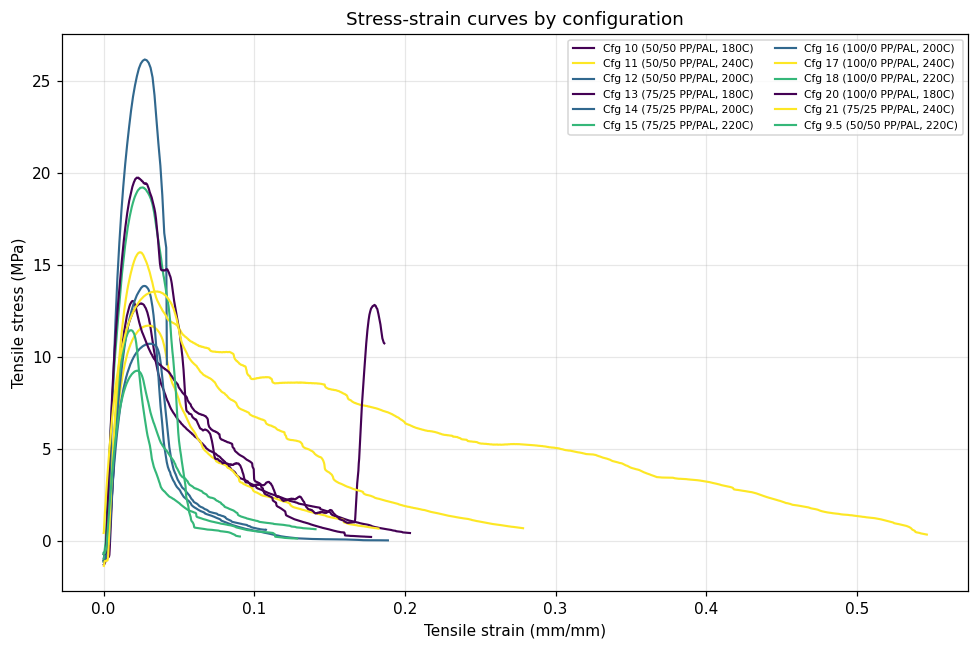

In [7]:
order = sorted(curves, key=lambda s: tensile_summary.set_index("sheet").loc[s, "config"])
seen = {}
fig, ax = plt.subplots(figsize=(9, 6))
cmap = plt.cm.viridis
temps = config_meta.set_index("config")["extr_temp_C"]
tmin, tmax = temps.min(), temps.max()

for s in order:
    row = tensile_summary.set_index("sheet").loc[s]
    cfg = row["config"]
    if cfg in seen:            # one curve per configuration to keep it readable
        continue
    seen[cfg] = True
    c = curves[s]
    color = cmap((row["extr_temp_C"] - tmin) / (tmax - tmin + 1e-9))
    ax.plot(c["strain"], c["stress_MPa"], color=color, lw=1.4,
            label=f"Cfg {cfg} ({int(row['pp_pct'])}/{int(row['pal_pct'])} PP/PAL, {int(row['extr_temp_C'])}C)")

ax.set_xlabel("Tensile strain (mm/mm)")
ax.set_ylabel("Tensile stress (MPa)")
ax.set_title("Stress-strain curves by configuration")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "tensile_stress_strain.png", dpi=150)
plt.show()

### 1.6 Mechanical properties vs. extrusion temperature

Young's modulus and ultimate tensile strength (UTS), replicate points plus per-config means.

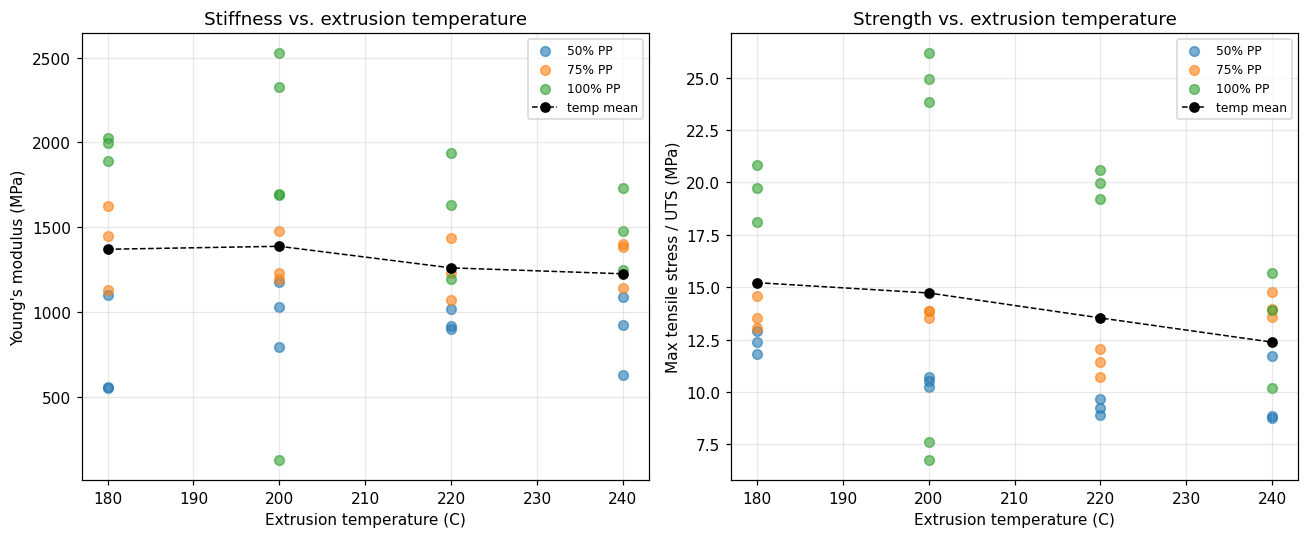

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col, lab in [
    (axes[0], "young_modulus_MPa", "Young's modulus (MPa)"),
    (axes[1], "max_tensile_stress_MPa", "Max tensile stress / UTS (MPa)"),
]:
    for pp, grp in tensile_summary.groupby("pp_pct"):
        ax.scatter(grp["extr_temp_C"], grp[col], s=40, alpha=0.6,
                   label=f"{int(pp)}% PP")
    means = tensile_summary.groupby("extr_temp_C")[col].mean()
    ax.plot(means.index, means.values, "k--", lw=1, marker="o", label="temp mean")
    ax.set_xlabel("Extrusion temperature (C)")
    ax.set_ylabel(lab)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_title("Stiffness vs. extrusion temperature")
axes[1].set_title("Strength vs. extrusion temperature")
fig.tight_layout()
fig.savefig(FIG_DIR / "tensile_properties_vs_temp.png", dpi=150)
plt.show()

### 1.7 Design space: max tensile stress vs. PAL% × extrusion temperature

Pulling **PAL %**, **extrusion temperature**, and **max tensile stress** out of every specimen
and viewing them together as a processing–property map. Because the experiment is a full
**3 × 4 grid** (PAL% ∈ {0, 25, 50} × temp ∈ {180, 200, 220, 240 °C}) we can show it three ways:
a gridded table, an annotated **heatmap**, and a **3D surface** with the individual specimens
overlaid. Max stress is a *magnitude*, so all use a single-hue perceptually-uniform (colorblind-safe)
color scale rather than a rainbow.


In [9]:
# Extract (PAL%, extrusion temperature, max tensile stress) for every specimen and grid it.
# The design is a full 3x4 grid: PAL% in {0, 25, 50} x temp in {180, 200, 220, 240},
# every cell populated (~3 replicates), so it maps cleanly to a heatmap / surface.
design = (tensile_summary
          .groupby(["pal_pct", "extr_temp_C"], as_index=False)
          .agg(max_stress_mean=("max_tensile_stress_MPa", "mean"),
               max_stress_std=("max_tensile_stress_MPa", "std"),
               modulus_mean=("young_modulus_MPa", "mean"),
               n=("replicate", "count")))
design.to_csv(PROC / "tensile" / "design_space_summary.csv", index=False)

# Axis order: temperatures ascending; PAL% descending so high-PAL is the top row.
temps = sorted(tensile_summary["extr_temp_C"].unique())
pals  = sorted(tensile_summary["pal_pct"].unique(), reverse=True)

grid_stress = (design.pivot(index="pal_pct", columns="extr_temp_C", values="max_stress_mean")
                     .reindex(index=pals, columns=temps))
print("Mean max tensile stress (MPa) — rows = PAL%, cols = extrusion temp (°C):")
grid_stress.round(2)


Mean max tensile stress (MPa) — rows = PAL%, cols = extrusion temp (°C):


extr_temp_C,180.0,200.0,220.0,240.0
pal_pct,,,,
50.0,12.37,10.48,9.27,9.78
25.0,13.71,13.74,11.41,14.08
0.0,19.55,17.86,19.91,13.26


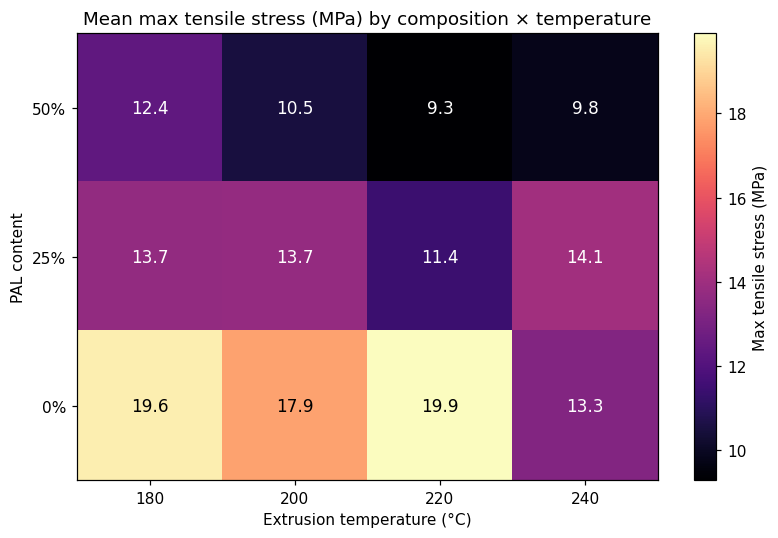

In [10]:
# Heatmap: mean max tensile stress over the PAL% x extrusion-temperature grid.
# Max stress is a MAGNITUDE -> single-hue perceptually-uniform (CVD-safe) sequential map,
# with each cell directly labeled and a labeled colorbar (no rainbow).
M = grid_stress.reindex(index=pals, columns=temps).values

fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(M, cmap="magma", aspect="auto")
ax.set_xticks(range(len(temps)), [f"{int(t)}" for t in temps])
ax.set_yticks(range(len(pals)),  [f"{int(p)}%" for p in pals])
ax.set_xlabel("Extrusion temperature (°C)")
ax.set_ylabel("PAL content")
ax.set_title("Mean max tensile stress (MPa) by composition × temperature")

mid = (np.nanmin(M) + np.nanmax(M)) / 2
for i in range(len(pals)):
    for j in range(len(temps)):
        v = M[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=11,
                    color="white" if v < mid else "black")

fig.colorbar(im, ax=ax).set_label("Max tensile stress (MPa)")
fig.tight_layout()
fig.savefig(FIG_DIR / "tensile_maxstress_heatmap.png", dpi=150)
plt.show()


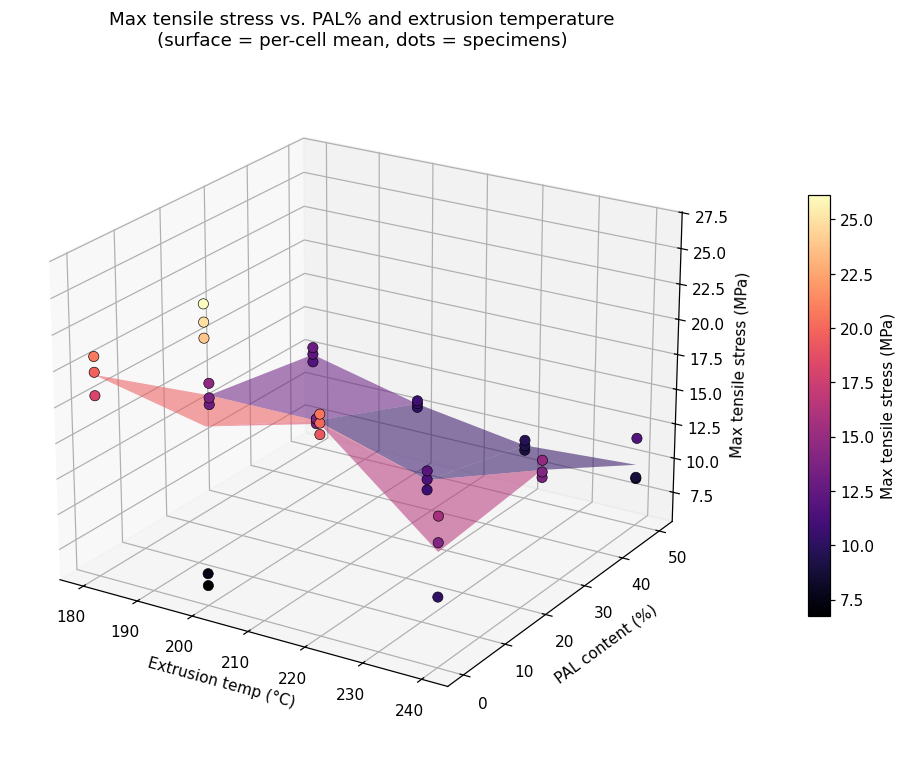

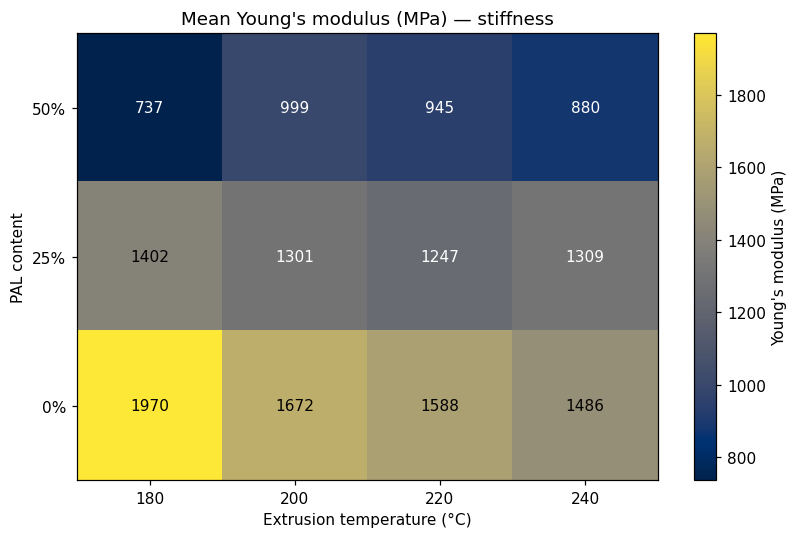

In [11]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers 3d projection)

# Mean-strength surface over the design grid + individual specimens scattered on top.
Tg, Pg = np.meshgrid(temps, pals)
Zg = grid_stress.reindex(index=pals, columns=temps).values

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(Tg, Pg, Zg, cmap="magma", alpha=0.55, edgecolor="none",
                vmin=np.nanmin(Zg), vmax=np.nanmax(Zg))
sc = ax.scatter(tensile_summary["extr_temp_C"], tensile_summary["pal_pct"],
                tensile_summary["max_tensile_stress_MPa"],
                c=tensile_summary["max_tensile_stress_MPa"], cmap="magma",
                s=45, edgecolor="k", linewidth=0.4, depthshade=False)
ax.set_xlabel("Extrusion temp (°C)")
ax.set_ylabel("PAL content (%)")
ax.set_zlabel("Max tensile stress (MPa)")
ax.set_title("Max tensile stress vs. PAL% and extrusion temperature\n(surface = per-cell mean, dots = specimens)")
ax.view_init(elev=22, azim=-58)
cbar = fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.1)
cbar.set_label("Max tensile stress (MPa)")
fig.tight_layout()
fig.savefig(FIG_DIR / "tensile_maxstress_3d.png", dpi=150)
plt.show()

# --- Companion: Young's modulus heatmap (example of "other visualization" #1) -------------
grid_mod = (design.pivot(index="pal_pct", columns="extr_temp_C", values="modulus_mean")
                  .reindex(index=pals, columns=temps))
Mm = grid_mod.values
fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(Mm, cmap="cividis", aspect="auto")
ax.set_xticks(range(len(temps)), [f"{int(t)}" for t in temps])
ax.set_yticks(range(len(pals)),  [f"{int(p)}%" for p in pals])
ax.set_xlabel("Extrusion temperature (°C)")
ax.set_ylabel("PAL content")
ax.set_title("Mean Young's modulus (MPa) — stiffness")
mmid = (np.nanmin(Mm) + np.nanmax(Mm)) / 2
for i in range(len(pals)):
    for j in range(len(temps)):
        v = Mm[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=10,
                    color="white" if v < mmid else "black")
fig.colorbar(im, ax=ax).set_label("Young's modulus (MPa)")
fig.tight_layout()
fig.savefig(FIG_DIR / "tensile_modulus_heatmap.png", dpi=150)
plt.show()


### 1.9 Other visualizations worth adding

The heatmap + 3D surface above answer *"how does strength depend on composition and
temperature?"* Other views worth building on the same data:

1. **Companion property heatmaps** — the same PAL% × temperature grid for **Young's modulus**
   (stiffness) and **strain-at-break** (ductility). Comparing the grids shows whether the best
   processing window is the same for stiffness, strength, and ductility, or a trade-off.
   *(A modulus heatmap is generated in the cell below as a starter.)*
2. **Strength vs. stiffness scatter** — UTS against Young's modulus, one point per specimen,
   colored by temperature or PAL%. Reveals the classic stiffness–strength trade-off.
3. **Replicate spread (box / strip plot)** per configuration — makes measurement scatter and
   outliers (e.g. the suspect `Config16_2` pull) visible, which a mean-only heatmap hides.
4. **Filled-contour** version of the design space — a smooth alternative to the discrete heatmap,
   good for suggesting an optimal window *between* the measured points.
5. **Interaction / main-effect plots** — mean strength vs. temperature with one line per PAL%
   level (and vice-versa) — shows whether temperature and composition interact.
6. **Rheology cross-view** — if the two studies are later linked: a viscosity heatmap
   (run × shear rate) or a viscosity-vs-temperature view.

Want any of these? The modulus companion heatmap below is included as an example of #1.


---
# Part 2 — Rheology study (viscosity vs. shear rate)

`recycled HDPE-PAL-viscosity.xlsx` holds rotational-rheometer flow-curve exports, one sheet per
run. Sheet names encode the **recycle level**: `5x*` = 5× recycled HDPE, `1x*` = 1× (shredded
3D-print stock). The export has no header row; by reconstructing viscosity = stress / shear-rate
we identified the physical columns:

| Column index | Quantity | Units |
|---|---|---|
| 6 | Shear stress | Pa |
| 7 | Shear rate   | 1/s |
| 8 | Viscosity    | Pa·s |

(Verified: e.g. 281.3 Pa ÷ 0.1 1/s = 2813 Pa·s.)

### 2.1 Parse every flow curve

In [12]:
def parse_viscosity_sheet(df):
    """Rows whose first cell is a measurement index -> (shear_rate, shear_stress, viscosity)."""
    idx = pd.to_numeric(df[0], errors="coerce")
    block = df[idx.notna()]
    out = pd.DataFrame({
        "point":          pd.to_numeric(block[0], errors="coerce"),
        "shear_stress_Pa": pd.to_numeric(block[6], errors="coerce"),
        "shear_rate_1_s":  pd.to_numeric(block[7], errors="coerce"),
        "viscosity_Pa_s":  pd.to_numeric(block[8], errors="coerce"),
    }).dropna(subset=["shear_rate_1_s", "viscosity_Pa_s"])
    out = out[out["shear_rate_1_s"] > 0].sort_values("shear_rate_1_s").reset_index(drop=True)
    return out

xlv = pd.ExcelFile(VISCOSITY_XLSX)
rheo_curves = {}
rheo_rows = []
for s in xlv.sheet_names:
    df = pd.read_excel(VISCOSITY_XLSX, sheet_name=s, header=None)
    curve = parse_viscosity_sheet(df)
    if curve.empty:
        continue
    recycle = "5x" if s.lower().startswith("5x") else ("1x" if s.lower().startswith("1x") else "?")
    safe = re.sub(r"[^0-9A-Za-z]+", "_", s).strip("_")
    curve.to_csv(RHEOLOGY_DIR / f"{safe}.csv", index=False)
    rheo_curves[s] = (recycle, curve)

    # Power-law fit  viscosity = K * rate^(n-1)  over the well-behaved low/mid-shear region.
    fit_region = curve[curve["shear_rate_1_s"] <= 10]
    if len(fit_region) >= 3:
        p = np.polyfit(np.log(fit_region["shear_rate_1_s"]),
                       np.log(fit_region["viscosity_Pa_s"]), 1)
        n_index = p[0] + 1          # flow behaviour index
        K = np.exp(p[1])
    else:
        n_index = K = np.nan
    rheo_rows.append({
        "sample": s, "recycle_level": recycle, "file": f"{safe}.csv",
        "n_points": len(curve),
        "shear_rate_min": curve["shear_rate_1_s"].min(),
        "shear_rate_max": curve["shear_rate_1_s"].max(),
        "viscosity_at_lowest_shear_Pa_s": curve["viscosity_Pa_s"].iloc[0],
        "powerlaw_K": K, "powerlaw_n": n_index,
    })

print(f"Parsed {len(rheo_curves)} flow curves -> {RHEOLOGY_DIR}")

Parsed 9 flow curves -> /data/zhq7531/IDEAL/UIC_NU_new/multi_task/processed_data/rheology/curves


### 2.2 Rheology summary

In [13]:
rheology_summary = pd.DataFrame(rheo_rows).sort_values(["recycle_level", "sample"]).reset_index(drop=True)
rheology_summary.to_csv(PROC / "rheology" / "rheology_summary.csv", index=False)
rheology_summary.round(3)

,sample,recycle_level,file,n_points,shear_rate_min,shear_rate_max,viscosity_at_lowest_shear_Pa_s,powerlaw_K,powerlaw_n
0,1x-using shredded 3D print,1x,1x_using_shredded_3D_print.csv,31,0.1,100.00,2063.0,1515.527,0.840
1,1x_test2,1x,1x_test2.csv,31,0.1,100.00,3114.0,2422.125,0.834
2,1x_test3,1x,1x_test3.csv,31,0.1,100.00,2311.0,1905.440,0.871
3,1x_test4,1x,1x_test4.csv,31,0.1,100.00,3319.0,2503.392,0.857
4,1x_test5,1x,1x_test5.csv,31,0.1,100.00,3748.0,2843.685,0.837
5,5x-recycled,5x,5x_recycled.csv,31,0.1,100.00,2813.0,1980.119,0.786
6,5x_test 2,5x,5x_test_2.csv,30,0.1,79.44,7008.0,4007.727,0.638
7,5x_test3,5x,5x_test3.csv,31,0.1,100.00,5883.0,3414.878,0.608
8,5x_test4,5x,5x_test4.csv,31,0.1,100.00,5241.0,3363.800,0.699


### 2.3 Viscosity flow curves (log–log)

Classic shear-thinning behaviour: viscosity drops as shear rate rises. The two recycle levels
are colored separately.

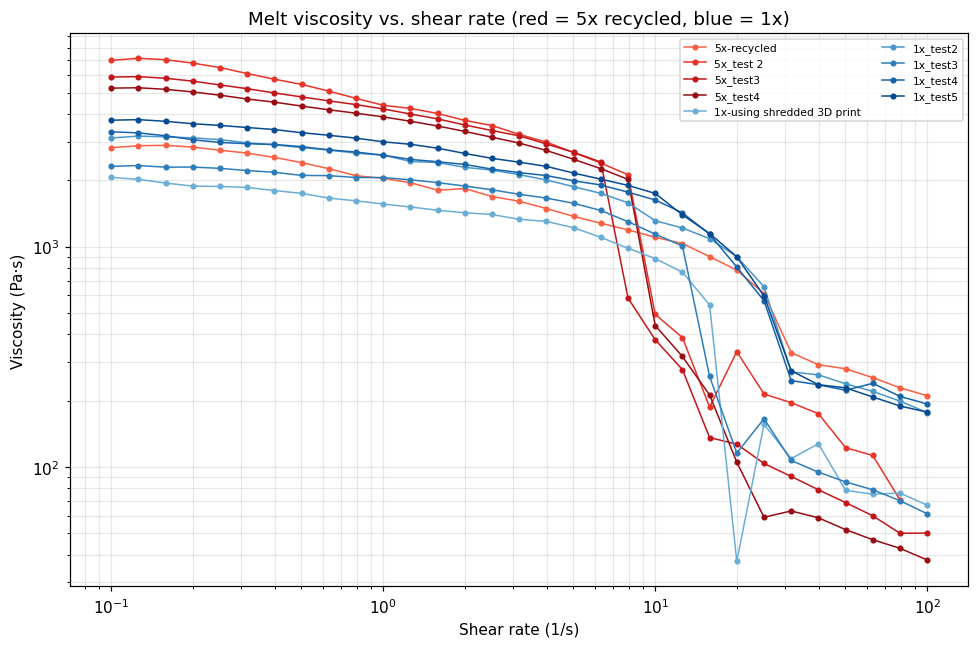

In [14]:
fig, ax = plt.subplots(figsize=(9, 6))
colors = {"5x": plt.cm.Reds, "1x": plt.cm.Blues}
counts = {"5x": 0, "1x": 0}
n_each = {k: sum(1 for v in rheo_curves.values() if v[0] == k) for k in ("5x", "1x")}

for s, (recycle, c) in rheo_curves.items():
    cmap = colors.get(recycle, plt.cm.Greys)
    counts[recycle] = counts.get(recycle, 0) + 1
    shade = 0.4 + 0.5 * counts[recycle] / max(n_each.get(recycle, 1), 1)
    ax.loglog(c["shear_rate_1_s"], c["viscosity_Pa_s"], marker="o", ms=3, lw=1,
              color=cmap(shade), label=s)

ax.set_xlabel("Shear rate (1/s)")
ax.set_ylabel("Viscosity (Pa·s)")
ax.set_title("Melt viscosity vs. shear rate (red = 5x recycled, blue = 1x)")
ax.grid(which="both", alpha=0.3)
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "rheology_flow_curves.png", dpi=150)
plt.show()

### 2.4 Recycle level comparison

Median viscosity vs. shear rate for each recycle level (curves share the same shear-rate grid),
showing how repeated recycling shifts the melt viscosity.

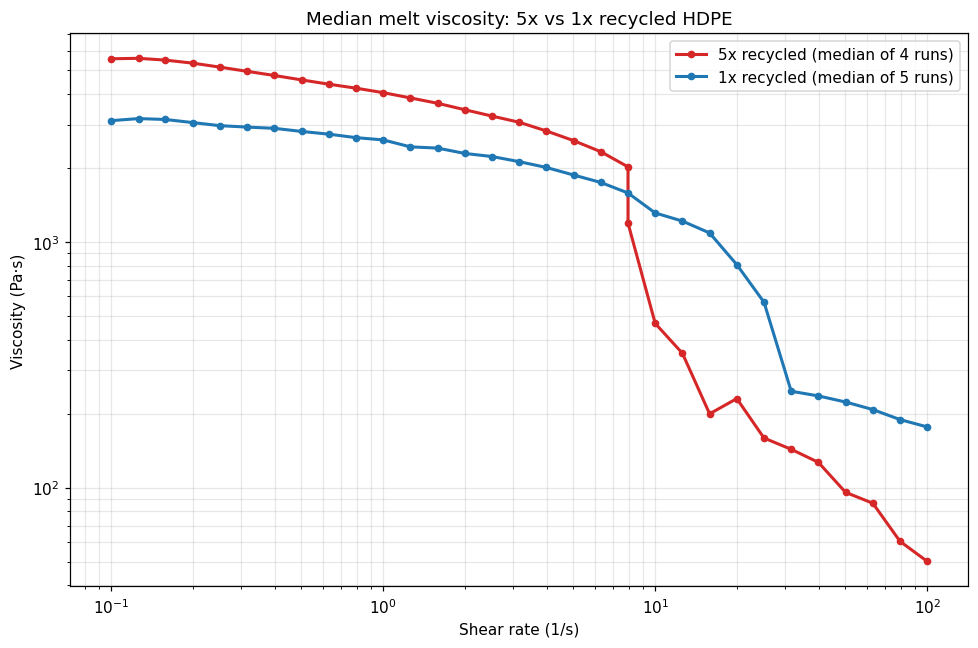

In [15]:
fig, ax = plt.subplots(figsize=(9, 6))
for level, style in [("5x", dict(color="C3")), ("1x", dict(color="C0"))]:
    members = [c for (lv, c) in rheo_curves.values() if lv == level]
    if not members:
        continue
    big = pd.concat(members)
    # bin onto the canonical log-spaced shear-rate grid and take the median
    big["rate_round"] = big["shear_rate_1_s"].round(3)
    med = big.groupby("rate_round")["viscosity_Pa_s"].median()
    ax.loglog(med.index, med.values, marker="o", ms=4, lw=2,
              label=f"{level} recycled (median of {len(members)} runs)", **style)
ax.set_xlabel("Shear rate (1/s)")
ax.set_ylabel("Viscosity (Pa·s)")
ax.set_title("Median melt viscosity: 5x vs 1x recycled HDPE")
ax.grid(which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "rheology_recycle_comparison.png", dpi=150)
plt.show()

---
# Outputs

Everything below now lives under `processed_data/` and is ready for downstream modelling/plotting.

In [16]:
for p in sorted(PROC.rglob("*")):
    if p.is_file():
        print(p.relative_to(PROJECT), f"({p.stat().st_size/1024:.1f} KB)")

print()
print(f"Tensile specimens : {len(tensile_summary)} across {tensile_summary['config'].nunique()} configurations")
print(f"Rheology runs     : {len(rheology_summary)}  (5x: {(rheology_summary.recycle_level=='5x').sum()}, "
      f"1x: {(rheology_summary.recycle_level=='1x').sum()})")

processed_data/figures/rheology_flow_curves.png (188.6 KB)
processed_data/figures/rheology_recycle_comparison.png (87.4 KB)
processed_data/figures/tensile_maxstress_3d.png (253.1 KB)
processed_data/figures/tensile_maxstress_heatmap.png (54.4 KB)
processed_data/figures/tensile_modulus_heatmap.png (59.1 KB)
processed_data/figures/tensile_properties_vs_temp.png (114.9 KB)
processed_data/figures/tensile_stress_strain.png (154.8 KB)
processed_data/rheology/curves/1x_test2.csv (0.7 KB)
processed_data/rheology/curves/1x_test3.csv (0.7 KB)
processed_data/rheology/curves/1x_test4.csv (0.7 KB)
processed_data/rheology/curves/1x_test5.csv (0.7 KB)
processed_data/rheology/curves/1x_using_shredded_3D_print.csv (0.7 KB)
processed_data/rheology/curves/5x_recycled.csv (0.8 KB)
processed_data/rheology/curves/5x_test3.csv (0.7 KB)
processed_data/rheology/curves/5x_test4.csv (0.7 KB)
processed_data/rheology/curves/5x_test_2.csv (0.7 KB)
processed_data/rheology/rheology_summary.csv (0.9 KB)
processed_data/